<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/Day_105_Embeddings_Practical_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 105/365 — Embeddings on a Real Text Dataset

Yesterday we learned:

`Text → Tokens → Token IDs`

Today we continue the pipeline:

`Token IDs → Embedding Vectors`

We will train a small **PyTorch text classifier** on the **UCI SMS Spam Collection** and inspect the vectors learned by `nn.Embedding`.

The notebook tries to load the full public UCI dataset when internet is available. It also contains a small real UCI-derived fallback sample so the lesson still runs offline.


In [1]:
# If needed in Colab:
# !pip install pandas scikit-learn torch matplotlib

import io
import re
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.decomposition import PCA


## 1. Load the real UCI SMS Spam Collection

In [2]:
UCI_URL = (
    "https://archive.ics.uci.edu/static/public/228/"
    "sms%2Bspam%2Bcollection.zip"
)

fallback_rows = [
    ("ham", "Ok lar... Joking wif u oni..."),
    ("ham", "Nah I don't think he goes to usf, he lives around here though"),
    ("ham", "Even my brother is not like to speak with me."),
    ("ham", "I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k?"),
    ("ham", "I HAVE A DATE ON SUNDAY WITH WILL!!"),
    ("ham", "Sorry, I'll call later in meeting."),
    ("ham", "Tell where you reached"),
    ("ham", "Fair enough, anything going on?"),
    ("ham", "I'm home."),
    ("ham", "Are you there in room."),
    ("spam", "Free entry in 2 a wkly comp to win FA Cup final tkts. Text FA to 87121."),
    ("spam", "WINNER!! As a valued network customer you have been selected to receive a prize reward!"),
    ("spam", "URGENT! You have won a FREE membership in our Prize Jackpot! Txt CLAIM now."),
    ("spam", "Your free ringtone is waiting to be collected. Text MIX to verify."),
]

try:
    raw = urllib.request.urlopen(
        UCI_URL,
        timeout=20
    ).read()

    with zipfile.ZipFile(
        io.BytesIO(raw)
    ) as z:

        with z.open(
            "SMSSpamCollection"
        ) as f:

            df = pd.read_csv(
                f,
                sep="\t",
                header=None,
                names=["label","text"]
            )

    source = "Full UCI SMS Spam Collection"

except Exception:

    df = pd.DataFrame(
        fallback_rows,
        columns=["label","text"]
    )

    source = "Offline real-data fallback sample"

print("Source:", source)
print("Rows:", len(df))
df.head()


Source: Full UCI SMS Spam Collection
Rows: 5572


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Token IDs are only integers

After tokenization, we may have:

`free → 42`

`meeting → 117`

Those integers do **not** contain semantic meaning by themselves.

The embedding layer learns a dense vector for every token ID.


In [3]:
def tokenize(text):
    return re.findall(
        r"\b\w+\b",
        str(text).lower()
    )

frequency = {}

for text in df["text"]:

    for token in tokenize(text):

        frequency[token] = (
            frequency.get(token,0) + 1
        )

min_frequency = (
    2 if len(df) > 100 else 1
)

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for token, count in sorted(
    frequency.items()
):

    if count >= min_frequency:

        vocab[token] = len(vocab)

print(
    "Vocabulary size:",
    len(vocab)
)


Vocabulary size: 4349


## 3. Convert SMS messages into token-ID sequences

In [4]:
MAX_LENGTH = 30

def encode(text):

    ids = [
        vocab.get(token,1)
        for token in tokenize(text)
    ]

    ids = ids[:MAX_LENGTH]

    ids += [0] * (
        MAX_LENGTH - len(ids)
    )

    return ids


X = np.array([
    encode(text)
    for text in df["text"]
])

y = (
    df["label"]
    .map({
        "ham": 0,
        "spam": 1
    })
    .to_numpy(
        dtype=np.float32
    )
)

print(X.shape)
print(y.shape)


(5572, 30)
(5572,)


## 4. Train/test split

In [5]:
if len(df) >= 50:

    X_train, X_test, y_train, y_test = (
        train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y
        )
    )

else:

    # Small offline fallback.
    # We keep all rows for demonstration.
    X_train = X_test = X
    y_train = y_test = y


## 5. Build a model with `nn.Embedding`

The important line is:

`nn.Embedding(vocab_size, embedding_dim)`

Think of it as a trainable matrix:

`[vocabulary size × embedding dimension]`

If token ID `42` enters the layer, row `42` is returned.


In [6]:
class EmbeddingClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=32
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.classifier = nn.Linear(
            embedding_dim,
            1
        )

    def forward(self,x):

        embeddings = self.embedding(x)

        mask = (
            x != 0
        ).unsqueeze(-1).float()

        summed = (
            embeddings * mask
        ).sum(dim=1)

        counts = (
            mask.sum(dim=1)
            .clamp(min=1)
        )

        message_embedding = (
            summed / counts
        )

        prediction = self.classifier(
            message_embedding
        )

        return (
            prediction,
            message_embedding
        )


## 6. Train on the real classification task

In [7]:
torch.manual_seed(42)

model = EmbeddingClassifier(
    vocab_size=len(vocab),
    embedding_dim=32
)

train_dataset = TensorDataset(
    torch.tensor(
        X_train,
        dtype=torch.long
    ),
    torch.tensor(
        y_train,
        dtype=torch.float32
    ).unsqueeze(1)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

epochs = (
    10 if len(df) >= 50 else 80
)

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for xb, yb in train_loader:

        optimizer.zero_grad()

        logits, _ = model(xb)

        loss = criterion(
            logits,
            yb
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    if (
        epoch == 0
        or (epoch + 1) % 2 == 0
    ):

        print(
            f"Epoch {epoch+1}: "
            f"loss={total_loss/len(train_loader):.4f}"
        )


Epoch 1: loss=0.3259
Epoch 2: loss=0.0819
Epoch 4: loss=0.0286
Epoch 6: loss=0.0132
Epoch 8: loss=0.0062
Epoch 10: loss=0.0033


## 7. Evaluate

In [8]:
model.eval()

with torch.no_grad():

    logits, _ = model(
        torch.tensor(
            X_test,
            dtype=torch.long
        )
    )

    probabilities = torch.sigmoid(
        logits
    )

    predictions = (
        probabilities >= 0.5
    ).int().numpy().ravel()

accuracy = accuracy_score(
    y_test,
    predictions
)

print(
    "Accuracy:",
    round(accuracy,4)
)

if len(df) >= 50:

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                "ham",
                "spam"
            ]
        )
    )


Accuracy: 0.9821
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.94      0.92      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



## 8. Inspect one learned embedding

Now we can directly inspect the vector learned for a word.


In [9]:
word = (
    "free"
    if "free" in vocab
    else next(
        token
        for token in vocab
        if token not in {
            "<PAD>",
            "<UNK>"
        }
    )
)

token_id = vocab[word]

embedding_vector = (
    model.embedding.weight[
        token_id
    ]
    .detach()
    .numpy()
)

print("Word:", word)
print("Token ID:", token_id)
print("Vector shape:", embedding_vector.shape)
print(
    "First 10 values:",
    np.round(
        embedding_vector[:10],
        3
    )
)


Word: free
Token ID: 1663
Vector shape: (32,)
First 10 values: [ 1.233  0.829 -1.039 -0.932  0.171 -0.333  0.886 -0.306  0.379 -1.533]


This is the key transition:

`word`

→ token ID

→ dense numerical vector

The vector values are **learned during training**.


## 9. Compare words with cosine similarity

In [10]:
def cosine_similarity(
    vector_a,
    vector_b
):

    numerator = np.dot(
        vector_a,
        vector_b
    )

    denominator = (
        np.linalg.norm(vector_a)
        * np.linalg.norm(vector_b)
        + 1e-9
    )

    return numerator / denominator


embedding_matrix = (
    model.embedding.weight
    .detach()
    .numpy()
)


def similarity(
    word_a,
    word_b
):

    a = embedding_matrix[
        vocab[word_a]
    ]

    b = embedding_matrix[
        vocab[word_b]
    ]

    return cosine_similarity(
        a,
        b
    )


available = [
    word
    for word in [
        "free",
        "win",
        "prize",
        "claim",
        "home",
        "call",
        "meeting"
    ]
    if word in vocab
]

for i in range(
    len(available)-1
):

    a = available[i]
    b = available[i+1]

    print(
        a,
        b,
        round(
            similarity(a,b),
            3
        )
    )


free win 0.199
win prize 0.353
prize claim 0.436
claim home -0.481
home call -0.075
call meeting -0.225


## 10. Visualize learned embeddings in 2D

Embedding vectors may have 32, 128, 768 or thousands of dimensions.

PCA lets us project them into 2D for visualization.

The 2D plot is only an approximation of the full embedding space.


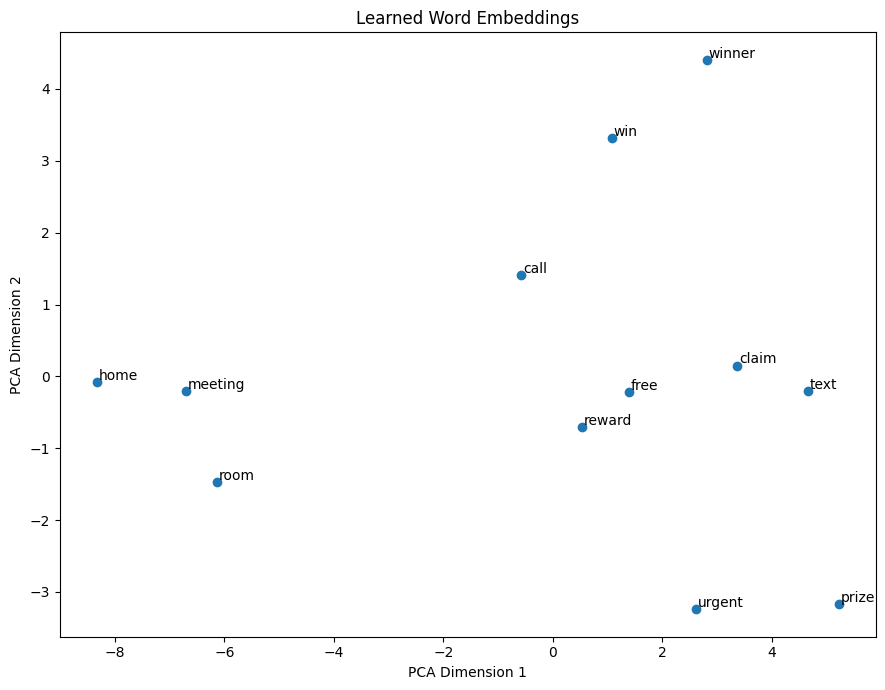

In [11]:
selected_words = [
    word
    for word in [
        "free",
        "win",
        "winner",
        "urgent",
        "claim",
        "reward",
        "home",
        "meeting",
        "call",
        "room",
        "text",
        "prize"
    ]
    if word in vocab
]

vectors = np.array([
    embedding_matrix[
        vocab[word]
    ]
    for word in selected_words
])

if len(selected_words) >= 2:

    coordinates = PCA(
        n_components=2
    ).fit_transform(
        vectors
    )

    plt.figure(
        figsize=(9,7)
    )

    plt.scatter(
        coordinates[:,0],
        coordinates[:,1]
    )

    for word, (
        x_position,
        y_position
    ) in zip(
        selected_words,
        coordinates
    ):

        plt.text(
            x_position + 0.03,
            y_position + 0.03,
            word
        )

    plt.xlabel(
        "PCA Dimension 1"
    )

    plt.ylabel(
        "PCA Dimension 2"
    )

    plt.title(
        "Learned Word Embeddings"
    )

    plt.tight_layout()
    plt.show()


## 11. Embeddings are learned because of the task

We did not manually tell the model:

`free` should have this vector.

During spam classification:

- forward propagation used the embeddings
- loss measured prediction error
- backpropagation computed gradients
- Adam updated the embedding matrix

So the vectors changed to become useful for the training objective.


## 12. Static embeddings vs contextual embeddings

This small model uses a **static embedding**.

The word:

`bank`

gets the same initial embedding regardless of context.

Modern Transformers then create **contextual representations**.

For example:

`river bank`

and:

`bank account`

start with token embeddings, but after Transformer layers their hidden representations become different because the surrounding context is different.

We will build toward this next.


## Simple takeaway

Token IDs are arbitrary integers.

Embeddings turn those IDs into trainable dense vectors.

`Token ID → Embedding vector`

The model learns these vectors so useful relationships can be represented numerically.

> **Tokenization gives language IDs. Embeddings give those IDs a learnable geometric representation.**


## References

- UCI SMS Spam Collection:
  https://archive.ics.uci.edu/dataset/228/sms+spam+collection

- PyTorch `nn.Embedding`:
  https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html

- Word2Vec:
  https://arxiv.org/abs/1301.3781

- Attention Is All You Need:
  https://arxiv.org/abs/1706.03762
